<a href="https://colab.research.google.com/github/sazedAawal/Cuckoo/blob/main/Cuckoo_Test_1_0_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install catboost -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.6 MB/s eta 0:00:00


In [2]:
import catboost as cb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [3]:
df_iter = pd.read_csv('/content/sample_data/5k_Iterations.csv')
df_3b = pd.read_csv("/content/sample_data/rays_3bounces.csv")
df_5b = pd.read_csv("/content/sample_data/rays_5bounces.csv")
df_9b = pd.read_csv("/content/sample_data/rays_9bounces.csv")

In [4]:
print("Datasets loaded successfully!")
print(f"5k Iterations Shape: {df_iter.shape}")
print(f"3-Bounce Rays Shape: {df_3b.shape}")
print(f"5-Bounce Rays Shape: {df_5b.shape}")
print(f"9-Bounce Rays Shape: {df_9b.shape}")

Datasets loaded successfully!
5k Iterations Shape: (1554, 11)
3-Bounce Rays Shape: (56, 16)
5-Bounce Rays Shape: (150, 16)
9-Bounce Rays Shape: (347, 16)


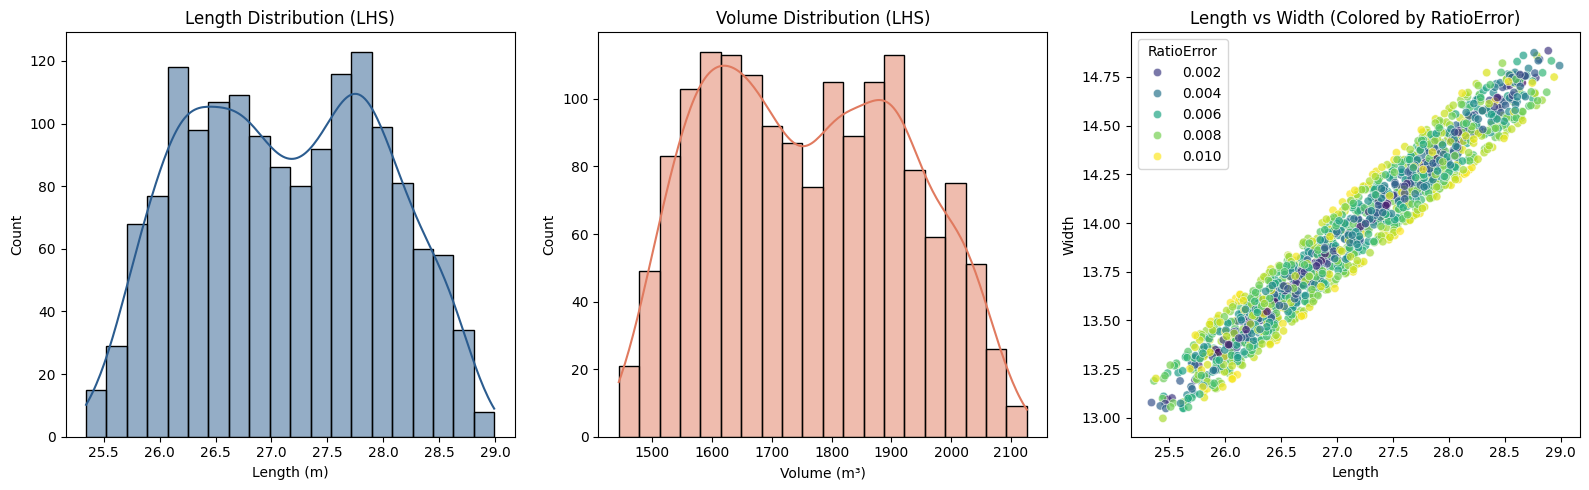

In [5]:
# Visualize parameter distributions and relationships from 5k_Iterations.csv
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(
    df_iter["Length"], ax=axes[0], color="#2b5c8f", kde=True, bins=20
)
axes[0].set_title("Length Distribution (LHS)")
axes[0].set_xlabel("Length (m)")

sns.histplot(
    df_iter["Volume"], ax=axes[1], color="#e07a5f", kde=True, bins=20
)

axes[1].set_title("Volume Distribution (LHS)")
axes[1].set_xlabel("Volume (m³)")

sns.scatterplot(
    data=df_iter,
    x="Length",
    y="Width",
    hue="RatioError",
    palette="viridis",
    ax=axes[2],
    alpha=0.7,
)

axes[2].set_title("Length vs Width (Colored by RatioError)")

plt.tight_layout()
plt.show()

/tmp/ipykernel_6271/3203270744.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


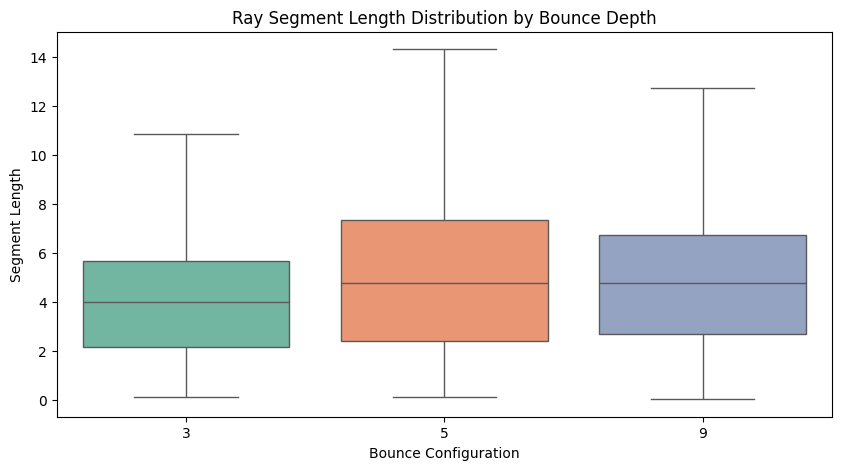

,BounceCount,RayCountConfig,TotalPathLength,MeanSegmentLength,MeanElevation
0,3,56,248.687364,4.440846,-2.882235
1,5,150,802.796389,5.351976,-0.038163
2,9,347,1776.575422,5.119814,-2.221631


In [6]:
# Tag bounce depth for comparison
df_3b["Bounce"] = 3
df_5b["Bounce"] = 5
df_9b["Bounce"] = 9
df_all_rays = pd.concat([df_3b, df_5b, df_9b], ignore_index=True)

# Visualize segment length distribution across 3, 5, and 9 bounces
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df_all_rays, x="Bounce", y="Length", palette="Set2", showfliers=False
)
plt.title("Ray Segment Length Distribution by Bounce Depth")
plt.xlabel("Bounce Configuration")
plt.ylabel("Segment Length")
plt.show()

# Summarize ray files for inspection
def summarize_rays(df_rays, bounce_count):
  return {
      "BounceCount": bounce_count,
      "RayCountConfig": len(df_rays),
      "TotalPathLength": df_rays["Length"].sum(),
      "MeanSegmentLength": df_rays["Length"].mean(),
      "MeanElevation": df_rays["Elevation"].mean(),
  }


summary_df = pd.DataFrame(
    [
        summarize_rays(df_3b, 3),
        summarize_rays(df_5b, 5),
        summarize_rays(df_9b, 9),
    ]
)
display(summary_df)

In [7]:
# Cross-join geometry iterations with ray summary configurations for the test workflow
master_rows = []

for _, geom_row in df_iter.iterrows():
  for _, ray_row in summary_df.iterrows():
    combined_row = {
        "Scale": geom_row["Scale"],
        "Length": geom_row["Length"],
        "Width": geom_row["Width"],
        "Height": geom_row["Height"],
        "SurfaceArea": geom_row["SurfaceArea"],
        "Volume": geom_row["Volume"],
        "L_W": geom_row["L_W"],
        "L_H": geom_row["L_H"],
        "W_H": geom_row["W_H"],
        "RatioError": geom_row["RatioError"],
        "BounceCount": ray_row["BounceCount"],
        "RayCountConfig": ray_row["RayCountConfig"],
        "TargetTotalPathLength": ray_row["TotalPathLength"],
    }
    master_rows.append(combined_row)

df_master = pd.DataFrame(master_rows)
print(f"Master training dataset created with shape: {df_master.shape}")
display(df_master.head())

Master training dataset created with shape: (4662, 13)


,Scale,Length,Width,Height,SurfaceArea,Volume,L_W,L_H,W_H,RatioError,BounceCount,RayCountConfig,TargetTotalPathLength
0,1.001796,27.001335,13.834438,4.566333,1120.036031,1705.745778,1.951748,5.913134,3.029660,0.008121,3.0,56.0,248.687364
1,1.001796,27.001335,13.834438,4.566333,1120.036031,1705.745778,1.951748,5.913134,3.029660,0.008121,5.0,150.0,802.796389
2,1.001796,27.001335,13.834438,4.566333,1120.036031,1705.745778,1.951748,5.913134,3.029660,0.008121,9.0,347.0,1776.575422
3,1.001615,26.920284,13.952685,4.640780,1130.585444,1743.124600,1.929398,5.800810,3.006539,0.005574,3.0,56.0,248.687364
4,1.001615,26.920284,13.952685,4.640780,1130.585444,1743.124600,1.929398,5.800810,3.006539,0.005574,5.0,150.0,802.796389


In [8]:
from sklearn.model_selection import train_test_split

# Define feature columns (X) and target (y)
feature_cols = [
    "Scale",
    "Length",
    "Width",
    "Height",
    "SurfaceArea",
    "Volume",
    "L_W",
    "L_H",
    "W_H",
    "RatioError",
    "BounceCount",
    "RayCountConfig",
]
target_col = "TargetTotalPathLength"

X = df_master[feature_cols]
y = df_master[target_col]

# Split data
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train a SINGLE CatBoost Regressor
model = cb.CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=200,
)

model.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=50)

# Save model as .cbm for C# / Grasshopper P/Invoke
model_filename = "cuckoo_acoustic_surrogate.cbm"
model.save_model(model_filename)
print(f"\nSuccess! Single model saved as '{model_filename}'")

# Download the model file automatically in Colab
from google.colab import files

files.download(model_filename)

0:	learn: 599.9396145	test: 600.8763328	best: 600.8763328 (0)	total: 47.9ms	remaining: 47.8s
200:	learn: 1.5568261	test: 2.1647883	best: 2.1647883 (200)	total: 668ms	remaining: 2.65s
400:	learn: 1.1463432	test: 1.8161415	best: 1.8161415 (400)	total: 1.38s	remaining: 2.06s
600:	learn: 0.9281466	test: 1.6607227	best: 1.6607227 (600)	total: 2.09s	remaining: 1.39s
800:	learn: 0.7893742	test: 1.5748182	best: 1.5748182 (800)	total: 3.16s	remaining: 786ms
999:	learn: 0.6907345	test: 1.5244621	best: 1.5244621 (999)	total: 4.36s	remaining: 0us

bestTest = 1.524462085
bestIteration = 999


Success! Single model saved as 'cuckoo_acoustic_surrogate.cbm'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>